In [1]:
import os
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"
os.environ["NUMEXPR_NUM_THREADS"] = "1"

PROJECT_RANDOM_STATE = 2627
print(f"PROJECT_RANDOM_STATE = {PROJECT_RANDOM_STATE}")
print("BLAS/OpenMP threads limited to 1 for reproducible notebook execution")

PROJECT_RANDOM_STATE = 2627
BLAS/OpenMP threads limited to 1 for reproducible notebook execution


# Practice 3 — Challenge B: Storage
## P3.3 Linear regression, P3.4 L1/L2 regularisation, and P3.5 comparison

This notebook keeps the Practice 2 target representation `z = log10(latency_ns)`, reads the canonical five-fold GroupKFold assignment from `storage_folds.csv`, and uses only the nine frozen source predictors. Preprocessing is fitted inside each training fold.

In [2]:
from pathlib import Path
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from threadpoolctl import threadpool_limits
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 180)

PROJECT_DIR = Path(".")
STORAGE_DIR = PROJECT_DIR / "datos" / "storage"
STORAGE_DEVELOPMENT_FILE = STORAGE_DIR / "storage_development.csv"
STORAGE_FOLDS_FILE = STORAGE_DIR / "storage_folds.csv"
COMPARISON_FILE = PROJECT_DIR / "comparativa.csv"

In [3]:
storage = pd.read_csv(STORAGE_DEVELOPMENT_FILE)
folds = pd.read_csv(STORAGE_FOLDS_FILE)
assert folds["row_id"].is_unique
assert set(folds["row_id"]) == set(storage["row_id"])
storage = storage.merge(folds, on="row_id", how="left", validate="one_to_one")
assert set(storage["fold_id"]) == {0, 1, 2, 3, 4}

NOMINAL_FEATURES = ["load_type", "io_type", "raid", "device_type"]
NUMERIC_FEATURES = ["block_size", "n_jobs", "iodepth", "read_fraction", "n_disks"]
MODEL_FEATURES = NOMINAL_FEATURES + NUMERIC_FEATURES
REFERENCE_LEVELS = ["random", "write", "4+1", "nvme"]
REFERENCE_LEVEL_BY_PREDICTOR = dict(zip(NOMINAL_FEATURES, REFERENCE_LEVELS))

y_ns = storage["latency_ns"].to_numpy()
y_z = np.log10(y_ns)

print("Rows:", len(storage))
print("Model source predictors:", MODEL_FEATURES)
print("Declared categorical reference levels:", REFERENCE_LEVEL_BY_PREDICTOR)

Rows: 12190
Model source predictors: ['load_type', 'io_type', 'raid', 'device_type', 'block_size', 'n_jobs', 'iodepth', 'read_fraction', 'n_disks']
Declared categorical reference levels: {'load_type': 'random', 'io_type': 'write', 'raid': '4+1', 'device_type': 'nvme'}


## Required interpretation route

The nominal references are declared explicitly: `load_type=random`, `io_type=write`, `raid=4+1`, and `device_type=nvme`. `4+1` is also the RAID reference used in the handout's interpretation example. Every declared reference occurs in every canonical training portion. Unknown categories would be handled with `handle_unknown="ignore"`, meaning all zeros and therefore the declared reference encoding.

All five numeric predictors are standardised on the training fold only and applied unchanged to validation. This common scale makes the numeric coefficients comparable as changes associated with one training-standard-deviation increase. The target stays fixed as `z = log10(latency_ns)`.

In [4]:
reference_checks = []
unseen_levels = []
for predictor, reference in REFERENCE_LEVEL_BY_PREDICTOR.items():
    for fold_id in sorted(storage["fold_id"].unique()):
        training_mask = storage["fold_id"] != fold_id
        validation_mask = ~training_mask
        reference_checks.append({
            "predictor": predictor,
            "reference_level": reference,
            "fold_id": fold_id,
            "training_count": int((training_mask & (storage[predictor] == reference)).sum()),
        })
        training_levels = set(storage.loc[training_mask, predictor].astype(str))
        validation_levels = set(storage.loc[validation_mask, predictor].astype(str))
        for level in sorted(validation_levels - training_levels):
            unseen_levels.append({"fold_id": fold_id, "predictor": predictor, "level": level})

reference_checks = pd.DataFrame(reference_checks)
assert (reference_checks["training_count"] > 0).all()
display(reference_checks)
print("Unseen validation levels:", unseen_levels if unseen_levels else "none")

,predictor,reference_level,fold_id,training_count
0,load_type,random,0,6465
1,load_type,random,1,6465
2,load_type,random,2,6450
3,load_type,random,3,6480
4,load_type,random,4,6480
5,io_type,write,0,5665
6,io_type,write,1,5665
7,io_type,write,2,5620
8,io_type,write,3,5650
9,io_type,write,4,5720


Unseen validation levels: none


In [5]:
def make_storage_preprocessor():
    return ColumnTransformer([
        ("nominal", OneHotEncoder(
            drop=REFERENCE_LEVELS,
            handle_unknown="ignore",
            sparse_output=False,
        ), NOMINAL_FEATURES),
        ("numeric", StandardScaler(), NUMERIC_FEATURES),
    ], verbose_feature_names_out=False)

# Fit each fold preprocessor once, strictly on that fold's training rows.
fold_cache = {}
for fold_id in sorted(storage["fold_id"].unique()):
    valid_idx = np.flatnonzero(storage["fold_id"].to_numpy() == fold_id)
    train_idx = np.flatnonzero(storage["fold_id"].to_numpy() != fold_id)
    preprocessor = make_storage_preprocessor()
    X_train = preprocessor.fit_transform(storage.iloc[train_idx][MODEL_FEATURES])
    X_valid = preprocessor.transform(storage.iloc[valid_idx][MODEL_FEATURES])
    fold_cache[fold_id] = (train_idx, valid_idx, preprocessor, X_train, X_valid)

## P3.3 — Unregularised linear regression on the canonical folds

For each canonical fold we fit `LinearRegression` on the transformed training matrix, predict `z` on validation, and report MAE(z), RMSE(z), R²(z), and physical-scale MAE only after converting each prediction with `10 ** z_hat`.

In [6]:
def evaluate_estimator(factory):
    rows = []
    for fold_id in sorted(fold_cache):
        train_idx, valid_idx, _, X_train, X_valid = fold_cache[fold_id]
        estimator = factory()
        start = time.perf_counter()
        with threadpool_limits(limits=1):
            estimator.fit(X_train, y_z[train_idx])
        fit_time = time.perf_counter() - start
        prediction_z = estimator.predict(X_valid)
        prediction_ns = 10 ** prediction_z
        rows.append({
            "fold_id": fold_id,
            "MAE_z": mean_absolute_error(y_z[valid_idx], prediction_z),
            "RMSE_z": np.sqrt(mean_squared_error(y_z[valid_idx], prediction_z)),
            "R2_z": r2_score(y_z[valid_idx], prediction_z),
            "MAE_ns": mean_absolute_error(y_ns[valid_idx], prediction_ns),
            "fit_time_s": fit_time,
        })
    return pd.DataFrame(rows)

linear_metrics = evaluate_estimator(lambda: LinearRegression())
display(linear_metrics.round(6))
print(f"Mean MAE(z): {linear_metrics['MAE_z'].mean():.6f}")
print(f"MAE(z) range: {(linear_metrics['MAE_z'].max() - linear_metrics['MAE_z'].min()):.6f}")
print(f"Mean RMSE(z): {linear_metrics['RMSE_z'].mean():.6f}")
print(f"Mean R2(z): {linear_metrics['R2_z'].mean():.6f}")
print(f"Mean MAE(ns), after 10**z_hat: {linear_metrics['MAE_ns'].mean():.3f}")

,fold_id,MAE_z,RMSE_z,R2_z,MAE_ns,fit_time_s
0,0,0.204719,0.278180,0.891466,1.797717e+07,0.016522
1,1,0.193664,0.266401,0.900268,1.700397e+07,0.003338
2,2,0.198352,0.273035,0.892584,1.698784e+07,0.002760
3,3,0.195265,0.264556,0.897630,1.267454e+07,0.002628
4,4,0.198728,0.269557,0.899832,1.680532e+07,0.002493


Mean MAE(z): 0.198146
MAE(z) range: 0.011054
Mean RMSE(z): 0.270346
Mean R2(z): 0.896356
Mean MAE(ns), after 10**z_hat: 16289769.151


In [7]:
full_preprocessor = make_storage_preprocessor()
X_full = full_preprocessor.fit_transform(storage[MODEL_FEATURES])
with threadpool_limits(limits=1):
    full_linear = LinearRegression().fit(X_full, y_z)
feature_names = full_preprocessor.get_feature_names_out()
coefficient_table = pd.DataFrame({
    "feature": feature_names,
    "coefficient_on_z": full_linear.coef_,
    "latency_factor_10_power_coefficient": 10 ** full_linear.coef_,
})

numeric_coefficients = coefficient_table[coefficient_table["feature"].isin(NUMERIC_FEATURES)].copy()
strongest_numeric = numeric_coefficients.iloc[numeric_coefficients["coefficient_on_z"].abs().argmax()]
raid_coefficients = coefficient_table[coefficient_table["feature"].str.startswith("raid_")].copy()
strongest_raid = raid_coefficients.iloc[raid_coefficients["coefficient_on_z"].abs().argmax()]

print("Numeric coefficients on the common standardised scale:")
display(numeric_coefficients.round(6))
print("RAID contrasts against reference RAID 4+1:")
display(raid_coefficients.round(6))

Numeric coefficients on the common standardised scale:


,feature,coefficient_on_z,latency_factor_10_power_coefficient
8,block_size,0.256679,1.805838
9,n_jobs,0.255525,1.801046
10,iodepth,0.263777,1.835597
11,read_fraction,-0.056872,0.877259
12,n_disks,-0.080129,0.831516


RAID contrasts against reference RAID 4+1:


,feature,coefficient_on_z,latency_factor_10_power_coefficient
2,raid_1+1,0.006661,1.015455
3,raid_2+1,-0.061459,0.868043
4,raid_2+2,-0.031396,0.930260
5,raid_4+2,-0.058559,0.873859
6,raid_8+2,-0.014685,0.966752


### P3.3 interpretation

The unregularised linear model has mean **MAE(z) = 0.198146**, mean **RMSE(z) = 0.270346**, mean **R²(z) = 0.896356**, and mean physical **MAE(ns) = 16289769.151** after predictions are inverted individually with `10 ** z_hat`.

1. **Numeric predictors on the common scale.** The largest absolute numeric coefficient is `iodepth`, with coefficient **0.263777** on `z`. A one-training-standard-deviation increase in `iodepth`, holding the other encoded predictors fixed, multiplies predicted physical latency by \(10^{0.263777}\) = **1.8356**. In this fitted model that is about an **83.6% increase** in predicted latency.

2. **One categorical predictor.** For `raid`, the declared reference is `4+1`. The largest absolute RAID contrast is `raid_2+1`, with coefficient **-0.061459**. Therefore an otherwise identical `2+1` configuration has predicted latency multiplied by \(10^{-0.061459}\) = **0.8680** relative to `4+1`, about **13.2% lower** predicted latency. This is a contrast to the named reference level, not an effect of RAID in isolation.

## P3.4 — L1 and L2 against the unregularised model

The unregularised `LinearRegression` remains the comparator. Ridge (L2) and Lasso (L1) use the same fold-fitted preprocessing and the same canonical folds. The declared strength grid is `alpha = logspace(-4, 2, 13)`. Selection inside this descriptive grid uses mean canonical MAE(z), but the final recommendation is argued from the shape of the design matrix rather than from a tiny score movement.

In [8]:
ALPHAS = np.logspace(-4, 2, 13)
regularisation_rows = []

for penalty_name in ["L2", "L1"]:
    for alpha in ALPHAS:
        if penalty_name == "L2":
            factory = lambda alpha=alpha: Ridge(alpha=alpha)
        else:
            factory = lambda alpha=alpha: Lasso(alpha=alpha, max_iter=20000, tol=1e-6)

        metrics = evaluate_estimator(factory)
        full_estimator = factory()
        with threadpool_limits(limits=1):
            full_estimator.fit(X_full, y_z)
        zero_count = int(np.sum(full_estimator.coef_ == 0.0)) if penalty_name == "L1" else np.nan
        regularisation_rows.append({
            "penalty": penalty_name,
            "alpha": alpha,
            **{f"fold_{int(row.fold_id)}": row.MAE_z for _, row in metrics.iterrows()},
            "mean_MAE_z": metrics["MAE_z"].mean(),
            "range_MAE_z": metrics["MAE_z"].max() - metrics["MAE_z"].min(),
            "fit_time_s": metrics["fit_time_s"].sum(),
            "zero_count_full_fit": zero_count,
        })

regularisation = pd.DataFrame(regularisation_rows)
best_l2 = regularisation[regularisation["penalty"] == "L2"].sort_values("mean_MAE_z").iloc[0]
best_l1 = regularisation[regularisation["penalty"] == "L1"].sort_values("mean_MAE_z").iloc[0]

display(regularisation[["penalty", "alpha", "mean_MAE_z", "range_MAE_z", "zero_count_full_fit"]].round(6))
print("Best L2 row on declared grid:")
display(best_l2)
print("Best L1 row on declared grid:")
display(best_l1)

,penalty,alpha,mean_MAE_z,range_MAE_z,zero_count_full_fit
0,L2,0.000100,0.198146,0.011054,NaN
1,L2,0.000316,0.198146,0.011054,NaN
2,L2,0.001000,0.198146,0.011054,NaN
3,L2,0.003162,0.198146,0.011054,NaN
4,L2,0.010000,0.198145,0.011054,NaN
5,L2,0.031623,0.198145,0.011054,NaN
6,L2,0.100000,0.198145,0.011053,NaN
7,L2,0.316228,0.198143,0.011050,NaN
8,L2,1.000000,0.198137,0.011042,NaN
9,L2,3.162278,0.198119,0.011014,NaN


Best L2 row on declared grid:


penalty                       L2
alpha                  31.622777
fold_0                  0.204501
fold_1                  0.193931
fold_2                  0.198175
fold_3                  0.194759
fold_4                  0.198731
mean_MAE_z               0.19802
range_MAE_z              0.01057
fit_time_s              0.150959
zero_count_full_fit          NaN
Name: 11, dtype: object

Best L1 row on declared grid:


penalty                      L1
alpha                  0.003162
fold_0                 0.205087
fold_1                 0.192313
fold_2                 0.197662
fold_3                 0.195031
fold_4                 0.197809
mean_MAE_z              0.19758
range_MAE_z            0.012773
fit_time_s             0.013156
zero_count_full_fit         2.0
Name: 16, dtype: object

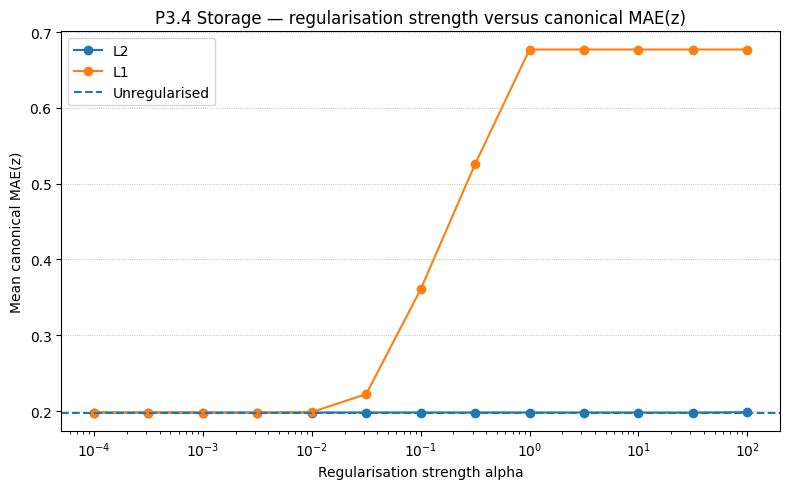

Exact-zero coefficient count under L1:


,alpha,zero_count_full_fit,mean_MAE_z
13,0.000100,0.0,0.198120
14,0.000316,0.0,0.198056
15,0.001000,1.0,0.197882
16,0.003162,2.0,0.197580
17,0.010000,5.0,0.198756
18,0.031623,5.0,0.222365
19,0.100000,8.0,0.360611
20,0.316228,12.0,0.525843
21,1.000000,13.0,0.676990
22,3.162278,13.0,0.676990


In [9]:
fig, ax = plt.subplots(figsize=(8, 5))
for penalty_name in ["L2", "L1"]:
    part = regularisation[regularisation["penalty"] == penalty_name]
    ax.plot(part["alpha"], part["mean_MAE_z"], marker="o", label=penalty_name)
ax.axhline(linear_metrics["MAE_z"].mean(), linestyle="--", label="Unregularised")
ax.set_xscale("log")
ax.set_xlabel("Regularisation strength alpha")
ax.set_ylabel("Mean canonical MAE(z)")
ax.set_title("P3.4 Storage — regularisation strength versus canonical MAE(z)")
ax.legend()
ax.grid(axis="y", linestyle=":", linewidth=0.6)
plt.tight_layout()
plt.show()

print("Exact-zero coefficient count under L1:")
display(regularisation[regularisation["penalty"] == "L1"][["alpha", "zero_count_full_fit", "mean_MAE_z"]].round(6))

In [10]:
design_rank = np.linalg.matrix_rank(X_full)
design_condition = np.linalg.cond(X_full)
print("Transformed design shape:", X_full.shape)
print("Matrix rank:", design_rank)
print("Condition number:", design_condition)
print("Numeric-predictor correlations:")
display(storage[NUMERIC_FEATURES].corr().round(3))

Transformed design shape: (12190, 13)
Matrix rank: 13
Condition number: 8.236950949768282
Numeric-predictor correlations:


,block_size,n_jobs,iodepth,read_fraction,n_disks
block_size,1.000,-0.183,-0.062,-0.243,-0.169
n_jobs,-0.183,1.000,-0.344,0.099,0.413
iodepth,-0.062,-0.344,1.000,-0.009,-0.371
read_fraction,-0.243,0.099,-0.009,1.000,0.084
n_disks,-0.169,0.413,-0.371,0.084,1.000


### P3.4 recommendation

The transformed full-data design has **12190 rows and 13 columns**, rank **13**, and condition number about **8.24**. It is therefore not a wide \(p \gg n\) problem and it is not close to rank deficiency. Some moderate predictor relationships exist, but there is no structural need for aggressive sparsity.

On the declared grid, the lowest mean MAE(z) is **0.198020** for L2 at \(\alpha=31.6228\) and **0.197580** for L1 at \(\alpha=0.00316228\). The selected L1 full fit sets **2** of the 13 transformed coefficients exactly to zero. These changes are tiny relative to the unregularised mean MAE(z) of **0.198146**.

**Recommendation:** keep the unregularised linear fit as the primary interpretable linear model. The design is small, full rank and reasonably conditioned, so the main justification for L1 sparsity is weak. If coefficient stabilisation under correlated predictors became an operational priority, Ridge would be the safer regularised alternative because it shrinks shared effects rather than selecting one predictor and zeroing another. The recommendation is based on the shape of the problem; the small score movements are supporting evidence, not the argument by themselves.

## P3.5 — Paired comparison against Practice 2, Challenge B

For MAE(z), lower is better, so the course convention is \(\delta_f = \mathrm{MAE}_{P2,f} - \mathrm{MAE}_{P3,f}\). A positive value would mean the Practice 3 candidate improved on the P2 KNN.

In [11]:
comparison = pd.read_csv(COMPARISON_FILE)
p2_knn = comparison[
    (comparison["milestone"] == "P2") &
    (comparison["challenge"] == "storage") &
    (comparison["family"] == "KNN")
].iloc[0]
p2_fold_mae = np.array([float(x) for x in p2_knn["primary_metric_per_fold"].split()])

linear_fold_mae = linear_metrics.sort_values("fold_id")["MAE_z"].to_numpy()
l2_fold_mae = np.array([best_l2[f"fold_{i}"] for i in range(5)], dtype=float)
l1_fold_mae = np.array([best_l1[f"fold_{i}"] for i in range(5)], dtype=float)

paired_storage = pd.DataFrame({
    "fold_id": range(5),
    "P2_KNN_MAE_z": p2_fold_mae,
    "P3_Linear_MAE_z": linear_fold_mae,
    "delta_KNN_minus_Linear": p2_fold_mae - linear_fold_mae,
    "P3_Ridge_MAE_z": l2_fold_mae,
    "delta_KNN_minus_Ridge": p2_fold_mae - l2_fold_mae,
    "P3_Lasso_MAE_z": l1_fold_mae,
    "delta_KNN_minus_Lasso": p2_fold_mae - l1_fold_mae,
})
display(paired_storage.round(6))

for label, delta in {
    "Linear": p2_fold_mae - linear_fold_mae,
    "Ridge": p2_fold_mae - l2_fold_mae,
    "Lasso": p2_fold_mae - l1_fold_mae,
}.items():
    print(label, "mean delta", f"{delta.mean():.6f}", "SD", f"{delta.std(ddof=0):.6f}", "range", f"{delta.max()-delta.min():.6f}")

# Append/replace P3 Storage rows while preserving all P2 rows and the Cyber P3 row.
def score_string(values):
    return " ".join(f"{value:.6f}" for value in values)

rows_to_append = pd.DataFrame([
    {
        "milestone": "P3", "challenge": "storage", "family": "LinearRegression", "route": "primary",
        "configuration": "LinearRegression(); target z=log10(latency_ns)",
        "preprocessing": "reference-dropped one-hot on 4 nominal predictors; StandardScaler on 5 numeric predictors; fitted inside each fold; target z",
        "features": "features.md: 9 distributed source predictors (frozen basis)",
        "validation": "canonical GroupKFold(5) assignment read from storage_folds.csv",
        "primary_metric_per_fold": score_string(linear_fold_mae),
        "primary_metric": f"{linear_fold_mae.mean():.6f}",
        "primary_metric_spread": f"range={linear_fold_mae.max()-linear_fold_mae.min():.6f}",
        "supporting_metrics": f"mean RMSE(z)={linear_metrics['RMSE_z'].mean():.6f}; mean R2(z)={linear_metrics['R2_z'].mean():.6f}; mean MAE_ns={linear_metrics['MAE_ns'].mean():.3f}",
        "fit_time_s": f"{linear_metrics['fit_time_s'].sum():.6f} total CV fit time",
        "interpretability": "standardised numeric coefficients and categorical contrasts against declared reference levels",
        "notes": "Unregularised linear comparator required by P3.4.",
    },
    {
        "milestone": "P3", "challenge": "storage", "family": "Ridge", "route": "primary",
        "configuration": f"Ridge(alpha={best_l2['alpha']:.8g}); target z=log10(latency_ns)",
        "preprocessing": "same P3 Storage reference-dropped one-hot + StandardScaler route; fitted inside each fold; target z",
        "features": "features.md: 9 distributed source predictors (frozen basis)",
        "validation": "canonical GroupKFold(5) assignment read from storage_folds.csv",
        "primary_metric_per_fold": score_string(l2_fold_mae),
        "primary_metric": f"{l2_fold_mae.mean():.6f}",
        "primary_metric_spread": f"range={l2_fold_mae.max()-l2_fold_mae.min():.6f}",
        "supporting_metrics": "P3.4 strength-versus-score curve; no exact-zero sparsity expected under L2",
        "fit_time_s": f"{best_l2['fit_time_s']:.6f} total CV fit time",
        "interpretability": "L2-shrunk coefficients on the same representation",
        "notes": "Best L2 alpha on the declared grid; recommendation is based on problem shape, not this score alone.",
    },
    {
        "milestone": "P3", "challenge": "storage", "family": "Lasso", "route": "primary",
        "configuration": f"Lasso(alpha={best_l1['alpha']:.8g}); target z=log10(latency_ns)",
        "preprocessing": "same P3 Storage reference-dropped one-hot + StandardScaler route; fitted inside each fold; target z",
        "features": "features.md: 9 distributed source predictors (frozen basis)",
        "validation": "canonical GroupKFold(5) assignment read from storage_folds.csv",
        "primary_metric_per_fold": score_string(l1_fold_mae),
        "primary_metric": f"{l1_fold_mae.mean():.6f}",
        "primary_metric_spread": f"range={l1_fold_mae.max()-l1_fold_mae.min():.6f}",
        "supporting_metrics": f"{int(best_l1['zero_count_full_fit'])} coefficients exactly zero in the full-data fit",
        "fit_time_s": f"{best_l1['fit_time_s']:.6f} total CV fit time",
        "interpretability": "sparse L1-shrunk coefficients on the same representation",
        "notes": "Best L1 alpha on the declared grid; sparsity is reported but is not by itself a reason to select the model.",
    },
])

mask_own = (comparison["milestone"] == "P3") & (comparison["challenge"] == "storage")
comparison = pd.concat([comparison.loc[~mask_own], rows_to_append], ignore_index=True)
comparison.to_csv(COMPARISON_FILE, index=False)
print("Updated", COMPARISON_FILE)

,fold_id,P2_KNN_MAE_z,P3_Linear_MAE_z,delta_KNN_minus_Linear,P3_Ridge_MAE_z,delta_KNN_minus_Ridge,P3_Lasso_MAE_z,delta_KNN_minus_Lasso
0,0,0.181473,0.204719,-0.023246,0.204501,-0.023028,0.205087,-0.023614
1,1,0.174995,0.193664,-0.018669,0.193931,-0.018936,0.192313,-0.017318
2,2,0.174313,0.198352,-0.024039,0.198175,-0.023862,0.197662,-0.023349
3,3,0.181022,0.195265,-0.014243,0.194759,-0.013737,0.195031,-0.014009
4,4,0.181381,0.198728,-0.017347,0.198731,-0.017350,0.197809,-0.016428


Linear mean delta -0.019509 SD 0.003677 range 0.009795
Ridge mean delta -0.019383 SD 0.003730 range 0.010124
Lasso mean delta -0.018944 SD 0.003861 range 0.009605
Updated comparativa.csv


### P3.5 fixed comparison questions — Challenge B

1. **Size and consistency of the paired change.** For the required unregularised linear model, the five deltas `P2 KNN MAE - P3 Linear MAE` are `-0.023246 -0.018669 -0.024039 -0.014243 -0.017347`. Their mean is **-0.019509**, population SD **0.003677**, and range **0.009795**. Every delta is negative, so the P3 linear model is worse than P2 KNN on every canonical fold. Ridge and Lasso remain negative as well (mean deltas **-0.019383** and **-0.018944**). These are descriptive fold comparisons, not significance tests.

2. **What comparison is being claimed.** This is a **pipeline comparison**. The source predictors, target representation and canonical folds are fixed, but P3 changes the categorical representation to explicit reference-dropped encoding and fits a parametric linear family. Without rerunning P2 KNN under exactly that representation, the score difference cannot be attributed to estimator family alone.

3. **What the new family can express.** Linear regression provides one global additive coefficient per transformed predictor. On the log10 target, a coefficient can be converted to a physical multiplicative latency factor with `10 ** coefficient`, which gives direct global interpretation unavailable from KNN's local neighbour averages.

4. **Cost of the new family.** The unregularised fit is computationally cheap and highly interpretable. P3.4 adds a regularisation grid and therefore tuning effort. L1 can remove coefficients and L2 can stabilise correlated effects, but both introduce a strength parameter and shrinkage changes the coefficient values being interpreted.

5. **Did the ordering of challenge difficulty change?** The two challenges use different metrics and targets, so their raw scores are not directly ordered. Within Storage, the result shows that the global additive linear structure does not match the local configuration-to-latency mapping as well as P2 KNN under the current basis.

6. **Would we ship the new model?** No. The P2 KNN has lower MAE(z) in every fold, and neither Ridge nor Lasso closes that gap. We would retain the linear model as an interpretation tool and reconsider shipping it only if deployment simplicity or coefficient transparency became more important than the observed predictive loss, or if later permitted model families improved the same canonical-fold evidence.

## Challenge B completion check

- P3.3 canonical-fold unregularised linear fit, MAE(z), RMSE(z), R²(z), physical MAE, and the two required coefficient interpretations: complete.
- P3.4 unregularised comparator, declared L1/L2 strength grid, curve, exact-zero counts and shape-based recommendation: complete.
- P3.5 paired fold differences and all six fixed comparison questions: complete.